#Análise da Mortalidade no Brasil

## Evolução temporal, desigualdades regionais e perfil demográfico das principais causas de óbito

### Objetivo
Analisar a mortalidade no Brasil a partir dos dados do Sistema de Informações sobre Mortalidade (SIM), investigando:

- a evolução dos óbitos ao longo do tempo;
- as diferenças de mortalidade entre estados, regiões e municípios;
- as principais causas de óbito segundo os grupos da CID-10;
- o perfil demográfico da mortalidade por faixa etária, sexo e raça/cor.

### Fontes de dados
Os dados utilizados são provenientes de bases públicas disponibilizadas pela Base dos Dados:

- Sistema de Informações sobre Mortalidade (SIM);
- população municipal do IBGE;
- diretório de municípios brasileiros.

### Período de análise
1996 a 2019.

### Ferramentas
- Google BigQuery — consulta, integração e modelagem dos dados;
- Python / Google Colab — tratamento, análise exploratória e visualizações;
- Looker Studio — construção do dashboard interativo.

In [ ]:
# ============================================================
# IMPORTAÇÃO DAS BIBLIOTECAS
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.cloud import bigquery
from google.colab import auth

# Configurações de exibição do pandas
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:,.2f}'.format)

print("Bibliotecas importadas com sucesso.")

Bibliotecas importadas com sucesso.


In [ ]:
# ============================================================
# AUTENTICAÇÃO NO GOOGLE CLOUD
# ============================================================

auth.authenticate_user()

print("Autenticação realizada com sucesso.")

Autenticação realizada com sucesso.


In [ ]:
# ============================================================
# CONEXÃO COM O BIGQUERY
# ============================================================

PROJECT_ID = "saude-sim-brasil"
DATASET_ID = "mortalidade_brasil"

client = bigquery.Client(project=PROJECT_ID)

print(f"Projeto conectado: {PROJECT_ID}")
print(f"Dataset utilizado: {DATASET_ID}")

Projeto conectado: saude-sim-brasil
Dataset utilizado: mortalidade_brasil


In [ ]:
# ============================================================
# TESTE DE CONEXÃO COM AS TABELAS ANALÍTICAS
# ============================================================

query_teste = """
SELECT
    'base_mortalidade_municipal' AS tabela,
    COUNT(*) AS total_linhas,
    SUM(numero_obitos) AS total_obitos
FROM `saude-sim-brasil.mortalidade_brasil.base_mortalidade_municipal`

UNION ALL

SELECT
    'base_perfil_mortalidade' AS tabela,
    COUNT(*) AS total_linhas,
    SUM(numero_obitos) AS total_obitos
FROM `saude-sim-brasil.mortalidade_brasil.base_perfil_mortalidade`
"""

df_teste = client.query(query_teste).to_dataframe()

df_teste

,tabela,total_linhas,total_obitos
0,base_mortalidade_municipal,132868,26294649
1,base_perfil_mortalidade,4626654,26294649


#Análise Exploratória de Dados (EDA)

A análise exploratória tem como objetivo identificar padrões temporais, geográficos e demográficos da mortalidade no Brasil entre 1996 e 2019.

## Perguntas de análise

1. **Como a mortalidade evoluiu no Brasil entre 1996 e 2019?**
   - Evolução do número de óbitos.
   - Evolução da taxa de mortalidade por 100 mil habitantes.

2. **Como as taxas de mortalidade estão distribuídas entre os municípios brasileiros?**
   - Média, mediana e dispersão.
   - Identificação de valores extremos (outliers).

3. **Existem desigualdades regionais na mortalidade?**
   - Comparação entre regiões e estados.
   - Evolução das taxas ao longo do tempo.

4. **Quais grupos da CID-10 concentram o maior número de óbitos?**
   - Participação dos principais grupos de causas.
   - Evolução das principais causas ao longo do período.

5. **Como a mortalidade varia de acordo com a faixa etária e o sexo?**
   - Distribuição dos óbitos por faixa etária.
   - Comparação entre homens e mulheres.

6. **Como a distribuição dos óbitos por raça/cor evoluiu ao longo do tempo?**
   - Participação das categorias de raça/cor.
   - Avaliação da presença de registros não informados.

> **Nota metodológica:** as análises de raça/cor exigem cautela devido à elevada proporção de registros sem informação nos primeiros anos da série histórica.

In [ ]:
# ============================================================
# EDA 1 — EVOLUÇÃO TEMPORAL DA MORTALIDADE NO BRASIL
# ============================================================

query_evolucao = """
SELECT
    ano,
    SUM(numero_obitos) AS total_obitos,
    SUM(populacao) AS populacao_total,

    ROUND(
        100000 * SAFE_DIVIDE(
            SUM(numero_obitos),
            SUM(populacao)
        ),
        2
    ) AS taxa_mortalidade_100k

FROM
    `saude-sim-brasil.mortalidade_brasil.base_mortalidade_municipal`

WHERE
    populacao IS NOT NULL

GROUP BY
    ano

ORDER BY
    ano
"""

df_evolucao = client.query(query_evolucao).to_dataframe()

df_evolucao

,ano,total_obitos,populacao_total,taxa_mortalidade_100k
0,1996,849354,156791040,541.71
1,1997,845641,159208186,531.15
2,1998,872508,161510685,540.22
3,1999,931586,164016689,567.98
4,2000,940061,169822453,553.56
5,2001,954897,172427983,553.79
6,2002,977926,174628247,560.00
7,2003,996442,176870445,563.37
8,2004,1017910,181569056,560.62
9,2005,1002359,184182992,544.22


In [ ]:
# ============================================================
# EDA 1 — ESTATÍSTICAS DA EVOLUÇÃO TEMPORAL
# ============================================================

resumo_evolucao = pd.DataFrame({
    'Indicador': [
        'Óbitos em 1996',
        'Óbitos em 2019',
        'Variação dos óbitos (%)',
        'Taxa em 1996',
        'Taxa em 2019',
        'Variação da taxa (%)',
        'Menor taxa do período',
        'Maior taxa do período',
        'Taxa média',
        'Taxa mediana'
    ],
    'Valor': [
        df_evolucao.iloc[0]['total_obitos'],
        df_evolucao.iloc[-1]['total_obitos'],
        (
            (df_evolucao.iloc[-1]['total_obitos'] /
             df_evolucao.iloc[0]['total_obitos']) - 1
        ) * 100,
        df_evolucao.iloc[0]['taxa_mortalidade_100k'],
        df_evolucao.iloc[-1]['taxa_mortalidade_100k'],
        (
            (df_evolucao.iloc[-1]['taxa_mortalidade_100k'] /
             df_evolucao.iloc[0]['taxa_mortalidade_100k']) - 1
        ) * 100,
        df_evolucao['taxa_mortalidade_100k'].min(),
        df_evolucao['taxa_mortalidade_100k'].max(),
        df_evolucao['taxa_mortalidade_100k'].mean(),
        df_evolucao['taxa_mortalidade_100k'].median()
    ]
})

resumo_evolucao

,Indicador,Valor
0,Óbitos em 1996,"849,354.00"
1,Óbitos em 2019,"1,347,263.00"
2,Variação dos óbitos (%),58.62
3,Taxa em 1996,541.71
4,Taxa em 2019,641.10
5,Variação da taxa (%),18.35
6,Menor taxa do período,531.15
7,Maior taxa do período,641.10
8,Taxa média,580.72
9,Taxa mediana,567.69


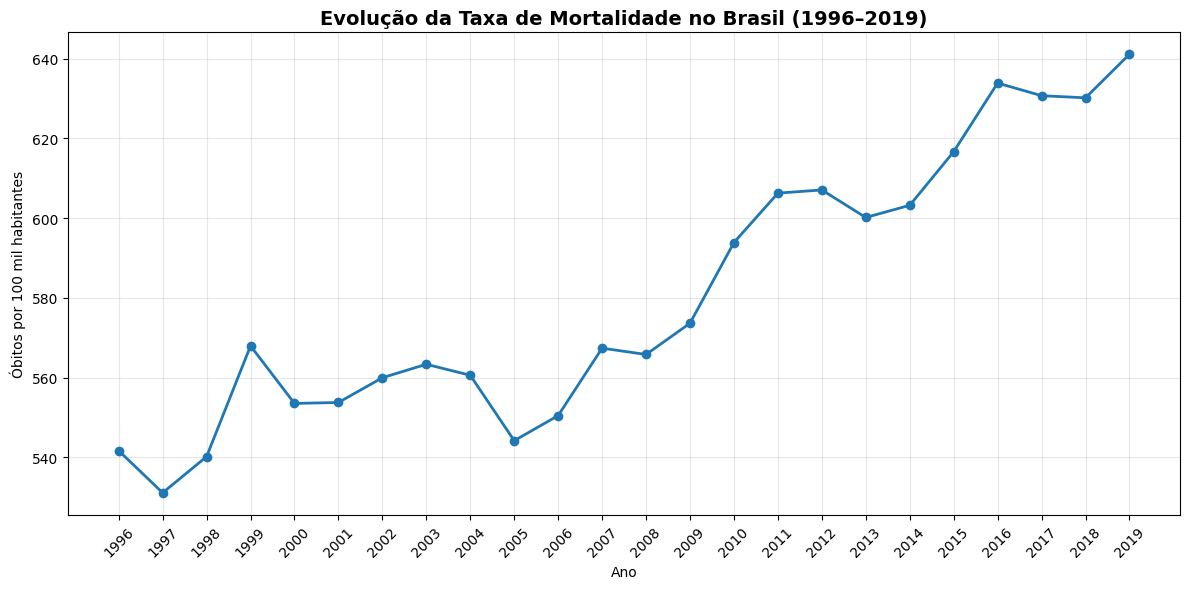

In [ ]:
# ============================================================
# EDA 1 — GRÁFICO DA EVOLUÇÃO DA TAXA DE MORTALIDADE
# ============================================================

plt.figure(figsize=(12, 6))

plt.plot(
    df_evolucao['ano'],
    df_evolucao['taxa_mortalidade_100k'],
    marker='o',
    linewidth=2
)

plt.title(
    'Evolução da Taxa de Mortalidade no Brasil (1996–2019)',
    fontsize=14,
    fontweight='bold'
)

plt.xlabel('Ano')
plt.ylabel('Óbitos por 100 mil habitantes')

plt.xticks(
    df_evolucao['ano'],
    rotation=45
)

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

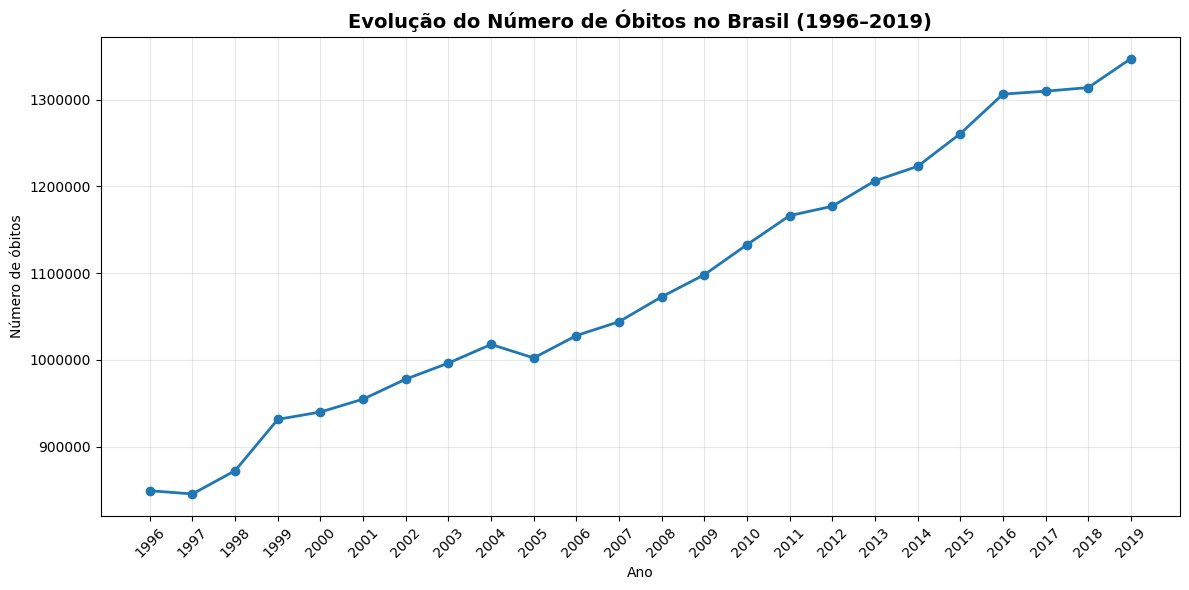

In [ ]:
# ============================================================
# EDA 1 — GRÁFICO DA EVOLUÇÃO DO NÚMERO DE ÓBITOS
# ============================================================

plt.figure(figsize=(12, 6))

plt.plot(
    df_evolucao['ano'],
    df_evolucao['total_obitos'],
    marker='o',
    linewidth=2
)

plt.title(
    'Evolução do Número de Óbitos no Brasil (1996–2019)',
    fontsize=14,
    fontweight='bold'
)

plt.xlabel('Ano')
plt.ylabel('Número de óbitos')

plt.xticks(
    df_evolucao['ano'],
    rotation=45
)

plt.ticklabel_format(
    style='plain',
    axis='y'
)

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Insight — Evolução temporal da mortalidade

Entre 1996 e 2019, o número de óbitos considerados na análise passou de **849.354 para 1.347.263**, representando um crescimento de aproximadamente **58,62%**.

A taxa de mortalidade também apresentou tendência de crescimento, passando de **541,71 para 641,10 óbitos por 100 mil habitantes**, um aumento de aproximadamente **18,35%** no período. A taxa média foi de **580,72**, enquanto a mediana foi de **567,69 óbitos por 100 mil habitantes**.

Embora existam oscilações ao longo da série histórica, observa-se uma elevação mais acentuada da taxa a partir do final dos anos 2000, atingindo o maior valor da série em 2019.

O crescimento do número absoluto de óbitos foi consideravelmente superior ao crescimento da taxa de mortalidade. Essa diferença evidencia a importância de considerar o tamanho da população ao realizar comparações temporais, já que o número absoluto de óbitos é influenciado também pela evolução populacional.

**Nota metodológica:** para o cálculo da taxa foram considerados apenas os registros município-ano com população disponível. Por isso, o total utilizado nessa análise pode ser inferior ao total geral de óbitos do SIM em alguns anos.

In [ ]:
# ============================================================
# EDA 2 — DISTRIBUIÇÃO DAS TAXAS MUNICIPAIS EM 2019
# ============================================================

query_municipios_2019 = """
SELECT
    id_municipio,
    municipio,
    sigla_uf,
    nome_uf,
    regiao,
    numero_obitos,
    populacao,
    taxa_mortalidade_100k

FROM
    `saude-sim-brasil.mortalidade_brasil.base_mortalidade_municipal`

WHERE
    ano = 2019
    AND populacao IS NOT NULL
    AND taxa_mortalidade_100k IS NOT NULL

ORDER BY
    taxa_mortalidade_100k DESC
"""

df_municipios_2019 = client.query(
    query_municipios_2019
).to_dataframe()

print(f"Municípios analisados: {len(df_municipios_2019):,}")

df_municipios_2019.head(10)

Municípios analisados: 5,570


,id_municipio,municipio,sigla_uf,nome_uf,regiao,numero_obitos,populacao,taxa_mortalidade_100k
0,3555901,Uru,SP,São Paulo,Sudeste,24,1165,"2,060.09"
1,4100459,Altamira do Paraná,PR,Paraná,Sul,38,1942,"1,956.75"
2,5204953,Campos Verdes,GO,Goiás,Centro-Oeste,37,2141,"1,728.16"
3,2413607,Severiano Melo,RN,Rio Grande do Norte,Nordeste,41,2440,"1,680.33"
4,4304853,Carlos Gomes,RS,Rio Grande do Sul,Sul,23,1377,"1,670.30"
5,2919959,Maetinga,BA,Bahia,Nordeste,51,3161,"1,613.41"
6,4305587,Colinas,RS,Rio Grande do Sul,Sul,39,2438,"1,599.67"
7,4312179,Mato Queimado,RS,Rio Grande do Sul,Sul,26,1648,"1,577.67"
8,4122107,Rio Bom,PR,Paraná,Sul,50,3203,"1,561.04"
9,5220264,São Miguel do Passa Quatro,GO,Goiás,Centro-Oeste,61,4057,"1,503.57"


In [ ]:
# ============================================================
# EDA 2 — ESTATÍSTICAS DESCRITIVAS
# ============================================================

df_municipios_2019['taxa_mortalidade_100k'].describe()

,taxa_mortalidade_100k
count,"5,570.00"
mean,675.30
std,197.08
min,98.01
25%,547.96
50%,664.20
75%,789.69
max,"2,060.09"


In [ ]:
# ============================================================
# EDA 2 — DISPERSÃO E IDENTIFICAÇÃO DE OUTLIERS
# Método: Intervalo Interquartil (IQR)
# ============================================================

taxas = df_municipios_2019['taxa_mortalidade_100k']

# Quartis
q1 = taxas.quantile(0.25)
q3 = taxas.quantile(0.75)

# Intervalo interquartil
iqr = q3 - q1

# Limites para identificação de outliers
limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

# Coeficiente de variação
coef_variacao = (taxas.std() / taxas.mean()) * 100

# Identificação dos outliers
df_outliers = df_municipios_2019[
    (taxas < limite_inferior) |
    (taxas > limite_superior)
].copy()

print(f"Q1: {q1:.2f}")
print(f"Q3: {q3:.2f}")
print(f"IQR: {iqr:.2f}")
print(f"Limite inferior: {limite_inferior:.2f}")
print(f"Limite superior: {limite_superior:.2f}")
print(f"Desvio-padrão: {taxas.std():.2f}")
print(f"Coeficiente de variação: {coef_variacao:.2f}%")
print(f"Número de outliers: {len(df_outliers)}")
print(f"Percentual de outliers: {(len(df_outliers) / len(df_municipios_2019)) * 100:.2f}%")

Q1: 547.96
Q3: 789.69
IQR: 241.73
Limite inferior: 185.37
Limite superior: 1152.29
Desvio-padrão: 197.08
Coeficiente de variação: 29.18%
Número de outliers: 110
Percentual de outliers: 1.97%


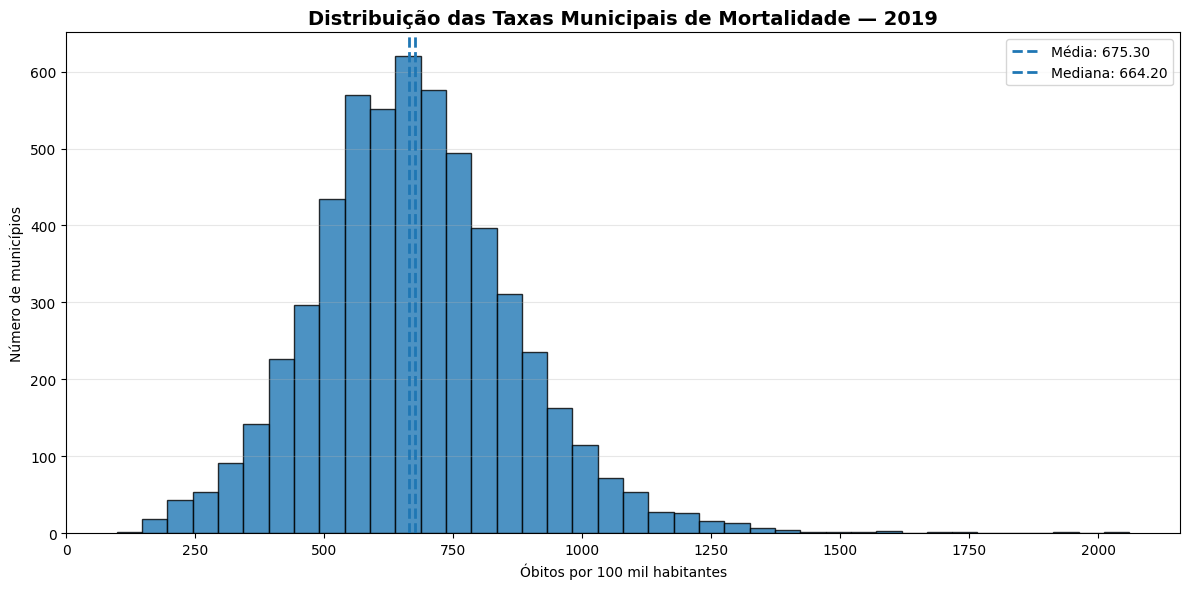

In [ ]:
# ============================================================
# EDA 2 — HISTOGRAMA DAS TAXAS MUNICIPAIS
# ============================================================

plt.figure(figsize=(12, 6))

plt.hist(
    df_municipios_2019['taxa_mortalidade_100k'],
    bins=40,
    edgecolor='black',
    alpha=0.8
)

plt.axvline(
    df_municipios_2019['taxa_mortalidade_100k'].mean(),
    linestyle='--',
    linewidth=2,
    label=f"Média: {df_municipios_2019['taxa_mortalidade_100k'].mean():.2f}"
)

plt.axvline(
    df_municipios_2019['taxa_mortalidade_100k'].median(),
    linestyle='--',
    linewidth=2,
    label=f"Mediana: {df_municipios_2019['taxa_mortalidade_100k'].median():.2f}"
)

plt.title(
    'Distribuição das Taxas Municipais de Mortalidade — 2019',
    fontsize=14,
    fontweight='bold'
)

plt.xlabel('Óbitos por 100 mil habitantes')
plt.ylabel('Número de municípios')

plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

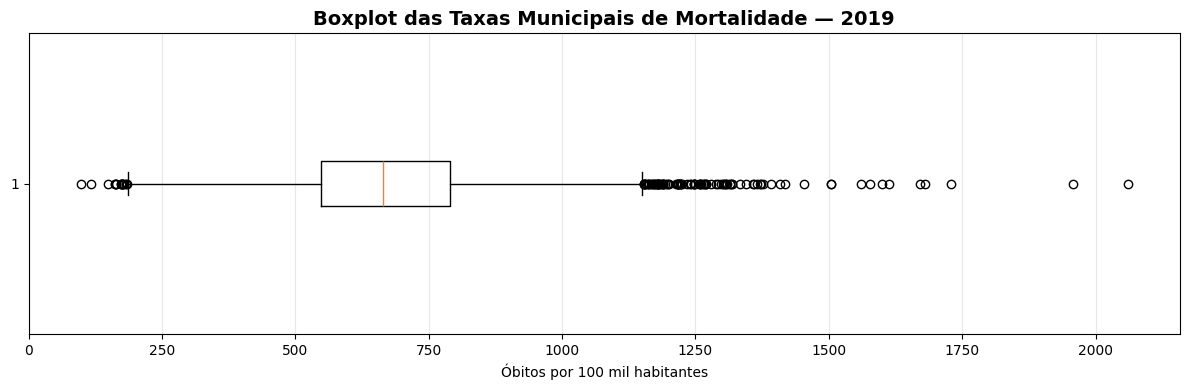

In [ ]:
# ============================================================
# EDA 2 — BOXPLOT DAS TAXAS MUNICIPAIS
# ============================================================

plt.figure(figsize=(12, 4))

plt.boxplot(
    df_municipios_2019['taxa_mortalidade_100k'],
    vert=False
)

plt.title(
    'Boxplot das Taxas Municipais de Mortalidade — 2019',
    fontsize=14,
    fontweight='bold'
)

plt.xlabel('Óbitos por 100 mil habitantes')

plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# EDA 2 — MUNICÍPIOS IDENTIFICADOS COMO OUTLIERS
# ============================================================

df_outliers[
    [
        'municipio',
        'sigla_uf',
        'regiao',
        'numero_obitos',
        'populacao',
        'taxa_mortalidade_100k'
    ]
].sort_values(
    'taxa_mortalidade_100k',
    ascending=False
).head(20)

,municipio,sigla_uf,regiao,numero_obitos,populacao,taxa_mortalidade_100k
0,Uru,SP,Sudeste,24,1165,"2,060.09"
1,Altamira do Paraná,PR,Sul,38,1942,"1,956.75"
2,Campos Verdes,GO,Centro-Oeste,37,2141,"1,728.16"
3,Severiano Melo,RN,Nordeste,41,2440,"1,680.33"
4,Carlos Gomes,RS,Sul,23,1377,"1,670.30"
5,Maetinga,BA,Nordeste,51,3161,"1,613.41"
6,Colinas,RS,Sul,39,2438,"1,599.67"
7,Mato Queimado,RS,Sul,26,1648,"1,577.67"
8,Rio Bom,PR,Sul,50,3203,"1,561.04"
9,São Miguel do Passa Quatro,GO,Centro-Oeste,61,4057,"1,503.57"


In [ ]:
# ============================================================
# EDA 2 — POPULAÇÃO DOS MUNICÍPIOS OUTLIERS
# ============================================================

resumo_pop_outliers = pd.DataFrame({
    'Grupo': ['Todos os municípios', 'Municípios outliers'],
    'População mediana': [
        df_municipios_2019['populacao'].median(),
        df_outliers['populacao'].median()
    ],
    'População média': [
        df_municipios_2019['populacao'].mean(),
        df_outliers['populacao'].mean()
    ]
})

resumo_pop_outliers

,Grupo,População mediana,População média
0,Todos os municípios,"11,631.00","37,728.39"
1,Municípios outliers,"3,304.50","5,710.72"


In [ ]:
# ============================================================
# EDA 2 — OUTLIERS POR FAIXA POPULACIONAL
# ============================================================

df_outliers['faixa_populacional'] = pd.cut(
    df_outliers['populacao'],
    bins=[0, 5000, 10000, 20000, 50000, float('inf')],
    labels=[
        'Até 5 mil',
        '5 a 10 mil',
        '10 a 20 mil',
        '20 a 50 mil',
        'Mais de 50 mil'
    ]
)

distribuicao_outliers = (
    df_outliers['faixa_populacional']
    .value_counts(sort=False)
    .rename_axis('Faixa populacional')
    .reset_index(name='Número de outliers')
)

distribuicao_outliers['Percentual (%)'] = (
    distribuicao_outliers['Número de outliers']
    / len(df_outliers)
    * 100
).round(2)

distribuicao_outliers

,Faixa populacional,Número de outliers,Percentual (%)
0,Até 5 mil,75,68.18
1,5 a 10 mil,20,18.18
2,10 a 20 mil,9,8.18
3,20 a 50 mil,6,5.45
4,Mais de 50 mil,0,0.00


### Insight — Distribuição e dispersão das taxas municipais

Em 2019, foram analisados **5.570 municípios brasileiros**. A taxa média de mortalidade foi de **675,30 óbitos por 100 mil habitantes**, enquanto a mediana foi de **664,20**, indicando uma leve assimetria à direita na distribuição.

O desvio-padrão foi de **197,08 óbitos por 100 mil habitantes**, e o coeficiente de variação atingiu **29,18%**, evidenciando uma dispersão relevante das taxas entre os municípios.

Pelo método do intervalo interquartil (IQR), foram identificados **110 municípios como outliers**, correspondendo a aproximadamente **1,97%** dos municípios analisados.

A investigação desses valores extremos mostrou forte associação com municípios de pequena população. Entre os outliers, **68,18% possuem até 5 mil habitantes** e **86,36% possuem até 10 mil habitantes**. Nenhum dos municípios classificados como outlier possui população superior a 50 mil habitantes.

Além disso, a população mediana dos municípios outliers foi de apenas **3.304,5 habitantes**, enquanto a mediana considerando todos os municípios foi de **11.631 habitantes**.

Esses resultados indicam que taxas brutas de mortalidade podem apresentar maior instabilidade em municípios pequenos, pois pequenas variações no número absoluto de óbitos produzem grandes alterações na taxa quando o denominador populacional é reduzido.

**Nota metodológica:** os outliers foram mantidos na base, pois não representam necessariamente erros. Sua interpretação deve considerar o tamanho populacional dos municípios.

In [ ]:
# ============================================================
# EDA 3 — TAXA DE MORTALIDADE POR REGIÃO EM 2019
# ============================================================

query_regioes_2019 = """
SELECT
    regiao,

    SUM(numero_obitos) AS total_obitos,
    SUM(populacao) AS populacao_total,

    ROUND(
        100000 * SAFE_DIVIDE(
            SUM(numero_obitos),
            SUM(populacao)
        ),
        2
    ) AS taxa_mortalidade_100k

FROM
    `saude-sim-brasil.mortalidade_brasil.base_mortalidade_municipal`

WHERE
    ano = 2019
    AND populacao IS NOT NULL
    AND regiao IS NOT NULL

GROUP BY
    regiao

ORDER BY
    taxa_mortalidade_100k DESC
"""

df_regioes_2019 = client.query(
    query_regioes_2019
).to_dataframe()

df_regioes_2019

,regiao,total_obitos,populacao_total,taxa_mortalidade_100k
0,Sudeste,614797,88371433,695.70
1,Sul,205960,29975984,687.08
2,Nordeste,352118,57071654,616.98
3,Centro-Oeste,88885,16297074,545.40
4,Norte,85503,18430980,463.91


In [ ]:
# ============================================================
# EDA 3 — TAXA DE MORTALIDADE POR UF EM 2019
# ============================================================

query_uf_2019 = """
SELECT
    sigla_uf,
    nome_uf,
    regiao,

    SUM(numero_obitos) AS total_obitos,
    SUM(populacao) AS populacao_total,

    ROUND(
        100000 * SAFE_DIVIDE(
            SUM(numero_obitos),
            SUM(populacao)
        ),
        2
    ) AS taxa_mortalidade_100k

FROM
    `saude-sim-brasil.mortalidade_brasil.base_mortalidade_municipal`

WHERE
    ano = 2019
    AND populacao IS NOT NULL
    AND nome_uf IS NOT NULL

GROUP BY
    sigla_uf,
    nome_uf,
    regiao

ORDER BY
    taxa_mortalidade_100k DESC
"""

df_uf_2019 = client.query(
    query_uf_2019
).to_dataframe()

df_uf_2019

,sigla_uf,nome_uf,regiao,total_obitos,populacao_total,taxa_mortalidade_100k
0,RJ,Rio de Janeiro,Sudeste,143641,17264943,831.98
1,RS,Rio Grande do Sul,Sul,89238,11377239,784.36
2,PB,Paraíba,Nordeste,27340,4018127,680.42
3,PE,Pernambuco,Nordeste,64041,9557071,670.09
4,SP,São Paulo,Sudeste,305858,45919049,666.08
5,MG,Minas Gerais,Sudeste,140892,21168791,665.56
6,PR,Paraná,Sul,74459,11433957,651.21
7,PI,Piauí,Nordeste,20500,3273227,626.29
8,BA,Bahia,Nordeste,93058,14873064,625.68
9,RN,Rio Grande do Norte,Nordeste,21765,3506853,620.64


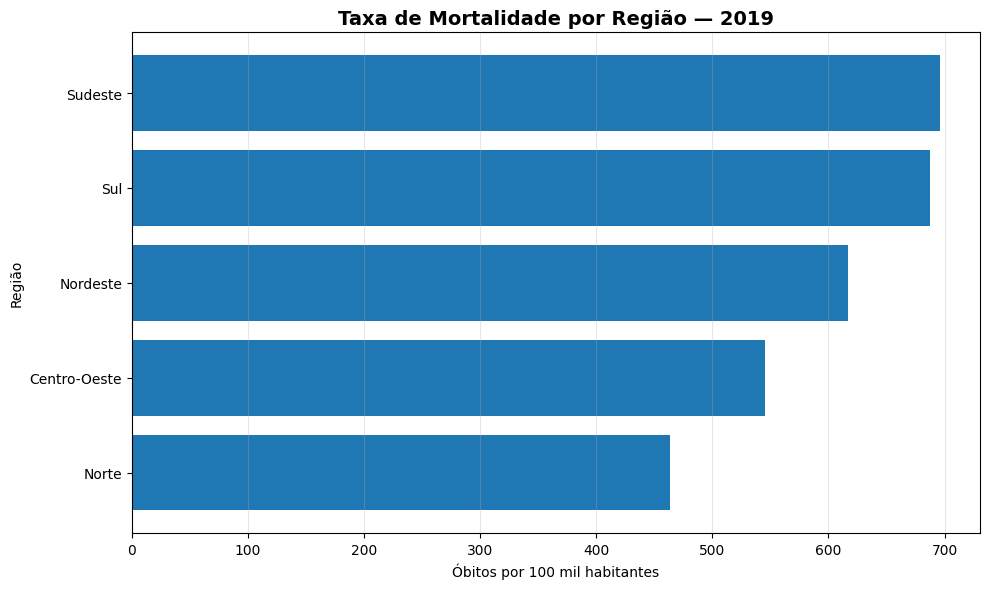

In [ ]:
# ============================================================
# EDA 3 — TAXA DE MORTALIDADE POR REGIÃO EM 2019
# ============================================================

df_plot_regioes = df_regioes_2019.sort_values(
    'taxa_mortalidade_100k',
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    df_plot_regioes['regiao'],
    df_plot_regioes['taxa_mortalidade_100k']
)

plt.title(
    'Taxa de Mortalidade por Região — 2019',
    fontsize=14,
    fontweight='bold'
)

plt.xlabel('Óbitos por 100 mil habitantes')
plt.ylabel('Região')

plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

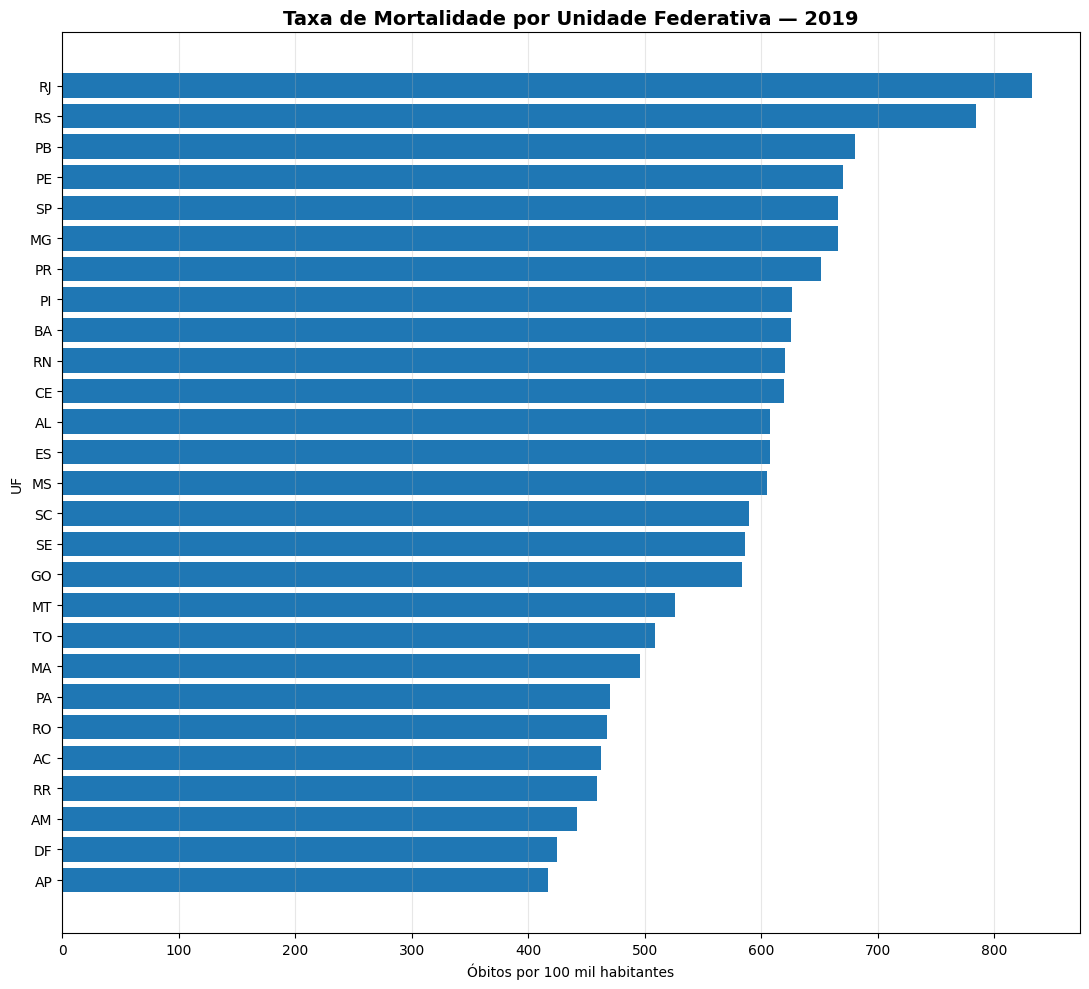

In [ ]:
# ============================================================
# EDA 3 — TAXA DE MORTALIDADE POR UF EM 2019
# ============================================================

df_plot_uf = df_uf_2019.sort_values(
    'taxa_mortalidade_100k',
    ascending=True
)

plt.figure(figsize=(11, 10))

plt.barh(
    df_plot_uf['sigla_uf'],
    df_plot_uf['taxa_mortalidade_100k']
)

plt.title(
    'Taxa de Mortalidade por Unidade Federativa — 2019',
    fontsize=14,
    fontweight='bold'
)

plt.xlabel('Óbitos por 100 mil habitantes')
plt.ylabel('UF')

plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# EDA 3 — EVOLUÇÃO DAS TAXAS POR REGIÃO
# ============================================================

query_evolucao_regioes = """
SELECT
    ano,
    regiao,

    SUM(numero_obitos) AS total_obitos,
    SUM(populacao) AS populacao_total,

    ROUND(
        100000 * SAFE_DIVIDE(
            SUM(numero_obitos),
            SUM(populacao)
        ),
        2
    ) AS taxa_mortalidade_100k

FROM
    `saude-sim-brasil.mortalidade_brasil.base_mortalidade_municipal`

WHERE
    populacao IS NOT NULL
    AND regiao IS NOT NULL

GROUP BY
    ano,
    regiao

ORDER BY
    ano,
    regiao
"""

df_evolucao_regioes = client.query(
    query_evolucao_regioes
).to_dataframe()

df_evolucao_regioes.head(10)

,ano,regiao,total_obitos,populacao_total,taxa_mortalidade_100k
0,1996,Centro-Oeste,48930,10494427,466.25
1,1996,Nordeste,200583,44618408,449.55
2,1996,Norte,38033,11174592,340.35
3,1996,Sudeste,412513,66989877,615.78
4,1996,Sul,149295,23513736,634.93
5,1997,Centro-Oeste,51184,10762068,475.60
6,1997,Nordeste,202781,45089692,449.73
7,1997,Norte,39753,11491582,345.93
8,1997,Sudeste,407128,68049056,598.29
9,1997,Sul,144795,23815788,607.98


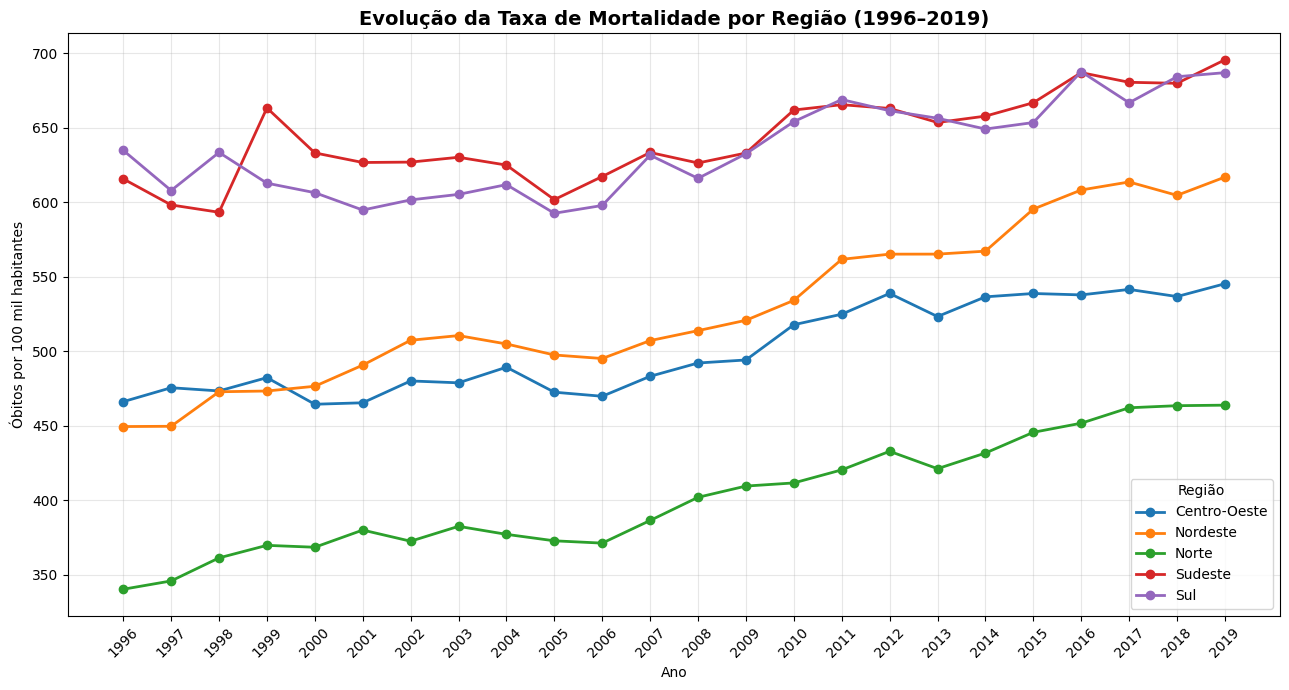

In [ ]:
# ============================================================
# EDA 3 — SÉRIE TEMPORAL DAS REGIÕES
# ============================================================

plt.figure(figsize=(13, 7))

for regiao in df_evolucao_regioes['regiao'].unique():

    dados = df_evolucao_regioes[
        df_evolucao_regioes['regiao'] == regiao
    ]

    plt.plot(
        dados['ano'],
        dados['taxa_mortalidade_100k'],
        marker='o',
        linewidth=2,
        label=regiao
    )

plt.title(
    'Evolução da Taxa de Mortalidade por Região (1996–2019)',
    fontsize=14,
    fontweight='bold'
)

plt.xlabel('Ano')
plt.ylabel('Óbitos por 100 mil habitantes')

plt.xticks(
    df_evolucao_regioes['ano'].unique(),
    rotation=45
)

plt.legend(title='Região')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

###  Insight — Desigualdades regionais na mortalidade

Em 2019, foram observadas diferenças expressivas nas taxas brutas de mortalidade entre as regiões brasileiras. O **Sudeste apresentou a maior taxa, com 695,70 óbitos por 100 mil habitantes**, seguido pelo **Sul, com 687,08**. Na outra extremidade, o **Norte apresentou 463,91 óbitos por 100 mil habitantes**.

A diferença entre Sudeste e Norte foi de aproximadamente **231,79 óbitos por 100 mil habitantes**, mostrando uma heterogeneidade territorial relevante.

A análise por Unidade Federativa revelou diferenças ainda maiores. Em 2019, o **Rio de Janeiro apresentou 831,98 óbitos por 100 mil habitantes**, seguido pelo **Rio Grande do Sul, com 784,36**. Entre as menores taxas observadas estavam **Amapá (416,68)**, **Distrito Federal (424,64)** e **Amazonas (442,05)**.

A análise temporal entre 1996 e 2019 mostra que as diferenças regionais persistem ao longo da série. Sul e Sudeste permanecem em patamares relativamente elevados durante grande parte do período, enquanto Norte, Nordeste e Centro-Oeste apresentam crescimento mais evidente das taxas ao longo dos anos.

**Nota metodológica:** as taxas utilizadas são brutas e não foram padronizadas por idade. Dessa forma, diferenças na estrutura etária das populações regionais e estaduais podem influenciar os resultados. Além disso, nos primeiros anos da série existem registros município-ano sem população disponível, o que exige cautela na comparação histórica.

In [ ]:
# ============================================================
# EDA 4 — PRINCIPAIS GRUPOS DE CAUSAS DE ÓBITO
# ============================================================

query_causas = """
SELECT
    grupo_causa,
    SUM(numero_obitos) AS total_obitos,

    ROUND(
        100 * SAFE_DIVIDE(
            SUM(numero_obitos),
            SUM(SUM(numero_obitos)) OVER()
        ),
        2
    ) AS percentual_obitos

FROM
    `saude-sim-brasil.mortalidade_brasil.base_perfil_mortalidade`

GROUP BY
    grupo_causa

ORDER BY
    total_obitos DESC
"""

df_causas = client.query(query_causas).to_dataframe()

df_causas

,grupo_causa,total_obitos,percentual_obitos
0,Doenças do aparelho circulatório,7359092,27.99
1,Neoplasias,3955347,15.04
2,Causas externas de morbidade e mortalidade,3238259,12.32
3,Doenças do aparelho respiratório,2778279,10.57
4,"Sintomas, sinais e achados anormais",2379961,9.05
5,"Doenças endócrinas, nutricionais e metabólicas",1475969,5.61
6,Doenças do aparelho digestivo,1291125,4.91
7,Doenças infecciosas e parasitárias,1184748,4.51
8,Afecções originadas no período perinatal,672254,2.56
9,Doenças do aparelho geniturinário,571434,2.17


In [ ]:
# ============================================================
# EDA 4 — PRINCIPAIS CATEGORIAS CID-10
# ============================================================

query_categorias_cid = """
SELECT
    categoria_cid,
    grupo_causa,
    SUM(numero_obitos) AS total_obitos,

    ROUND(
        100 * SAFE_DIVIDE(
            SUM(numero_obitos),
            SUM(SUM(numero_obitos)) OVER()
        ),
        2
    ) AS percentual_obitos

FROM
    `saude-sim-brasil.mortalidade_brasil.base_perfil_mortalidade`

GROUP BY
    categoria_cid,
    grupo_causa

ORDER BY
    total_obitos DESC

LIMIT 20
"""

df_categorias_cid = client.query(
    query_categorias_cid
).to_dataframe()

df_categorias_cid

,categoria_cid,grupo_causa,total_obitos,percentual_obitos
0,I21,Doenças do aparelho circulatório,1779604,6.77
1,J18,Doenças do aparelho respiratório,1092084,4.15
2,R98,"Sintomas, sinais e achados anormais",1048603,3.99
3,I64,Doenças do aparelho circulatório,1028021,3.91
4,E14,"Doenças endócrinas, nutricionais e metabólicas",984040,3.74
5,R99,"Sintomas, sinais e achados anormais",901727,3.43
6,X95,Causas externas de morbidade e mortalidade,769754,2.93
7,J44,Doenças do aparelho respiratório,747805,2.84
8,I50,Doenças do aparelho circulatório,674273,2.56
9,C34,Neoplasias,487075,1.85


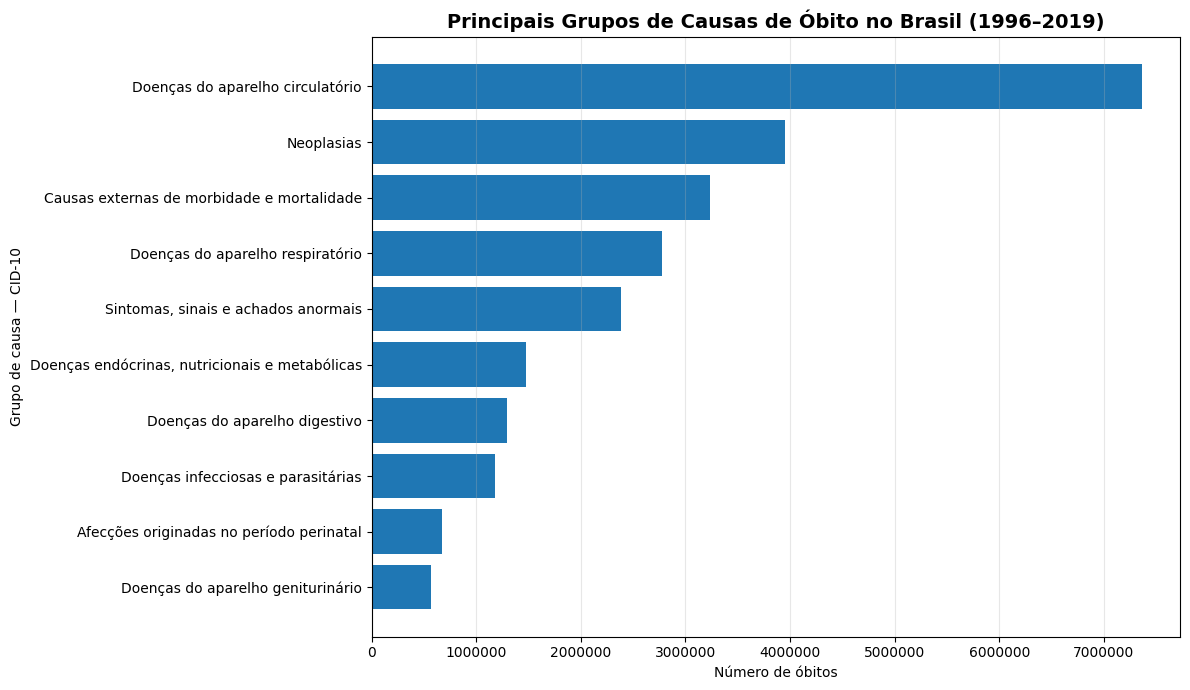

In [ ]:
# ============================================================
# EDA 4 — TOP 10 GRUPOS DE CAUSAS
# ============================================================

df_top10_causas = (
    df_causas
    .head(10)
    .sort_values('total_obitos', ascending=True)
)

plt.figure(figsize=(12, 7))

plt.barh(
    df_top10_causas['grupo_causa'],
    df_top10_causas['total_obitos']
)

plt.title(
    'Principais Grupos de Causas de Óbito no Brasil (1996–2019)',
    fontsize=14,
    fontweight='bold'
)

plt.xlabel('Número de óbitos')
plt.ylabel('Grupo de causa — CID-10')

plt.ticklabel_format(
    style='plain',
    axis='x'
)

plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# EDA 4 — EVOLUÇÃO DOS PRINCIPAIS GRUPOS DE CAUSAS
# ============================================================

query_evolucao_causas = """
WITH causas_ano AS (

    SELECT
        ano,
        grupo_causa,
        SUM(numero_obitos) AS total_obitos

    FROM
        `saude-sim-brasil.mortalidade_brasil.base_perfil_mortalidade`

    GROUP BY
        ano,
        grupo_causa
),

total_ano AS (

    SELECT
        ano,
        SUM(total_obitos) AS total_obitos_ano

    FROM causas_ano

    GROUP BY ano
)

SELECT
    c.ano,
    c.grupo_causa,
    c.total_obitos,

    ROUND(
        100 * SAFE_DIVIDE(
            c.total_obitos,
            t.total_obitos_ano
        ),
        2
    ) AS percentual_ano

FROM causas_ano c

LEFT JOIN total_ano t
    ON c.ano = t.ano

ORDER BY
    c.ano,
    c.total_obitos DESC
"""

df_evolucao_causas = client.query(
    query_evolucao_causas
).to_dataframe()

df_evolucao_causas.head(15)

,ano,grupo_causa,total_obitos,percentual_ano
0,1996,Doenças do aparelho circulatório,249613,27.46
1,1996,"Sintomas, sinais e achados anormais",137039,15.08
2,1996,Causas externas de morbidade e mortalidade,119156,13.11
3,1996,Neoplasias,103408,11.38
4,1996,Doenças do aparelho respiratório,88436,9.73
5,1996,Doenças infecciosas e parasitárias,52511,5.78
6,1996,Doenças do aparelho digestivo,39035,4.29
7,1996,Afecções originadas no período perinatal,37299,4.10
8,1996,"Doenças endócrinas, nutricionais e metabólicas",36590,4.03
9,1996,Doenças do aparelho geniturinário,12792,1.41


In [ ]:
# ============================================================
# EDA 4 — SELEÇÃO DOS 5 PRINCIPAIS GRUPOS
# ============================================================

top5_causas = (
    df_causas
    .head(5)['grupo_causa']
    .tolist()
)

df_top5_evolucao = df_evolucao_causas[
    df_evolucao_causas['grupo_causa'].isin(top5_causas)
].copy()

top5_causas

['Doenças do aparelho circulatório',
 'Neoplasias',
 'Causas externas de morbidade e mortalidade',
 'Doenças do aparelho respiratório',
 'Sintomas, sinais e achados anormais']

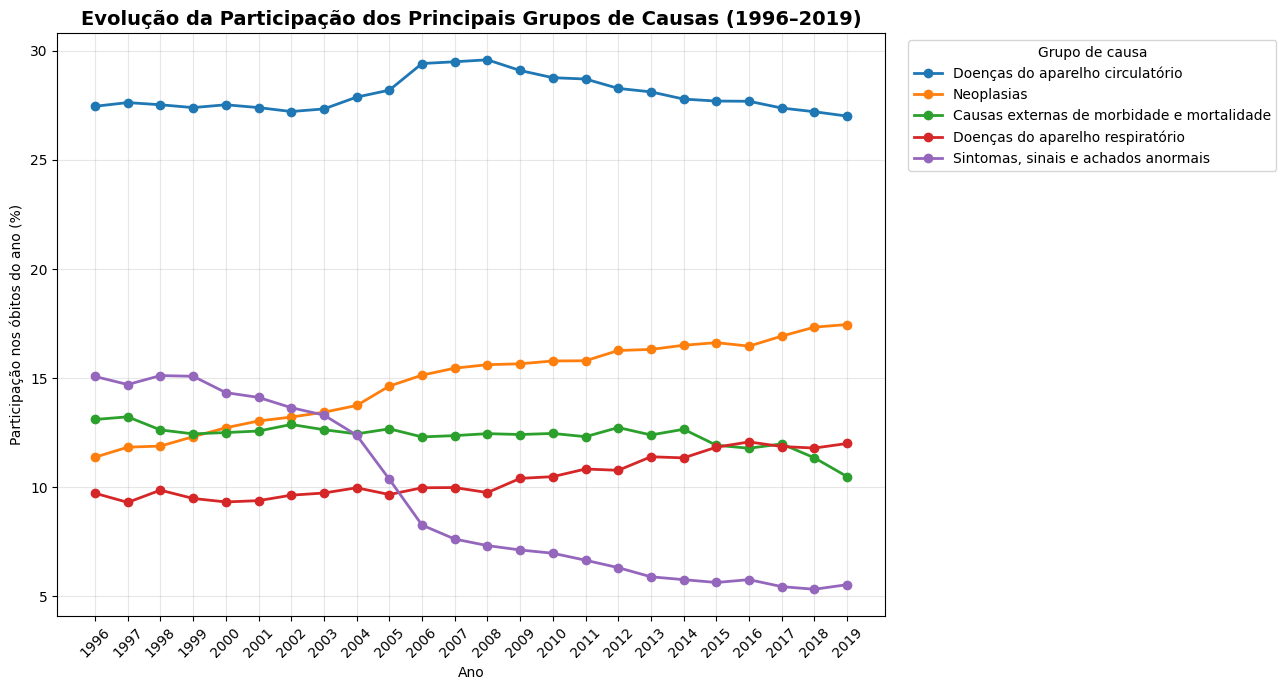

In [ ]:
# ============================================================
# EDA 4 — EVOLUÇÃO DA PARTICIPAÇÃO DOS PRINCIPAIS GRUPOS
# ============================================================

plt.figure(figsize=(13, 7))

for causa in top5_causas:

    dados = df_top5_evolucao[
        df_top5_evolucao['grupo_causa'] == causa
    ]

    plt.plot(
        dados['ano'],
        dados['percentual_ano'],
        marker='o',
        linewidth=2,
        label=causa
    )

plt.title(
    'Evolução da Participação dos Principais Grupos de Causas (1996–2019)',
    fontsize=14,
    fontweight='bold'
)

plt.xlabel('Ano')
plt.ylabel('Participação nos óbitos do ano (%)')

plt.xticks(
    sorted(df_top5_evolucao['ano'].unique()),
    rotation=45
)

plt.legend(
    title='Grupo de causa',
    bbox_to_anchor=(1.02, 1),
    loc='upper left'
)

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# EDA 4 — COMPARAÇÃO 1996 × 2019
# ============================================================

comparacao_causas = (
    df_top5_evolucao[
        df_top5_evolucao['ano'].isin([1996, 2019])
    ]
    .pivot(
        index='grupo_causa',
        columns='ano',
        values='percentual_ano'
    )
    .reset_index()
)

comparacao_causas['variacao_pontos_percentuais'] = (
    comparacao_causas[2019] - comparacao_causas[1996]
)

comparacao_causas = comparacao_causas.sort_values(
    'variacao_pontos_percentuais',
    ascending=False
)

comparacao_causas

ano,grupo_causa,1996,2019,variacao_pontos_percentuais
3,Neoplasias,11.38,17.46,6.08
2,Doenças do aparelho respiratório,9.73,12.01,2.28
1,Doenças do aparelho circulatório,27.46,27.01,-0.45
0,Causas externas de morbidade e mortalidade,13.11,10.49,-2.62
4,"Sintomas, sinais e achados anormais",15.08,5.54,-9.54


### Insight — Principais causas de mortalidade

Entre 1996 e 2019, as **doenças do aparelho circulatório** constituíram o principal grupo de causas de óbito no Brasil, totalizando **7.359.092 mortes**, equivalentes a **27,99%** dos óbitos registrados no período.

Na sequência aparecem **neoplasias (15,04%)**, **causas externas de morbidade e mortalidade (12,32%)** e **doenças do aparelho respiratório (10,57%)**. Juntos, esses quatro grupos concentraram aproximadamente **65,9% dos óbitos** da série histórica.

A análise temporal revelou mudanças importantes na composição da mortalidade. As **neoplasias** aumentaram sua participação de **11,38% em 1996 para 17,46% em 2019**, crescimento de **6,08 pontos percentuais**. As **doenças do aparelho respiratório** também ganharam participação, passando de **9,73% para 12,01%** (+2,28 p.p.).

As **doenças do aparelho circulatório**, embora tenham permanecido como principal grupo, apresentaram relativa estabilidade na participação, passando de **27,46% em 1996 para 27,01% em 2019**.

As **causas externas de morbidade e mortalidade** reduziram sua participação de **13,11% para 10,49%** (-2,62 p.p.).

A maior redução ocorreu no grupo **“Sintomas, sinais e achados anormais”**, cuja participação caiu de **15,08% em 1996 para 5,54% em 2019**, uma redução de **9,54 pontos percentuais**.

Essa evolução demonstra que, embora as doenças circulatórias tenham permanecido predominantes, a composição das causas de mortalidade sofreu mudanças relevantes ao longo dos 24 anos analisados.

**Nota metodológica:** a redução do grupo “Sintomas, sinais e achados anormais” não deve ser atribuída automaticamente a melhorias na qualidade dos registros, diagnóstico ou preenchimento das declarações de óbito sem uma investigação específica dessas hipóteses.

In [ ]:
# ============================================================
# EDA 5 — DISTRIBUIÇÃO DOS ÓBITOS POR FAIXA ETÁRIA
# ============================================================

query_faixa_etaria = """
SELECT
    faixa_etaria,
    SUM(numero_obitos) AS total_obitos,

    ROUND(
        100 * SAFE_DIVIDE(
            SUM(numero_obitos),
            SUM(SUM(numero_obitos)) OVER()
        ),
        2
    ) AS percentual_obitos

FROM
    `saude-sim-brasil.mortalidade_brasil.base_perfil_mortalidade`

GROUP BY
    faixa_etaria

ORDER BY
    total_obitos DESC
"""

df_faixa_etaria = client.query(
    query_faixa_etaria
).to_dataframe()

df_faixa_etaria

,faixa_etaria,total_obitos,percentual_obitos
0,65-79 anos,7574056,28.80
1,80 anos ou mais,6452951,24.54
2,45-64 anos,6334284,24.09
3,25-44 anos,3089571,11.75
4,0-14 anos,1590200,6.05
5,15-24 anos,1117153,4.25
6,Não informado,136434,0.52


In [ ]:
# ============================================================
# EDA 5 — DISTRIBUIÇÃO DOS ÓBITOS POR SEXO
# ============================================================

query_sexo = """
SELECT
    sexo_descricao,
    SUM(numero_obitos) AS total_obitos,

    ROUND(
        100 * SAFE_DIVIDE(
            SUM(numero_obitos),
            SUM(SUM(numero_obitos)) OVER()
        ),
        2
    ) AS percentual_obitos

FROM
    `saude-sim-brasil.mortalidade_brasil.base_perfil_mortalidade`

GROUP BY
    sexo_descricao

ORDER BY
    total_obitos DESC
"""

df_sexo = client.query(query_sexo).to_dataframe()

df_sexo

,sexo_descricao,total_obitos,percentual_obitos
0,Masculino,15024234,57.14
1,Feminino,11254186,42.80
2,Não informado,16229,0.06


In [ ]:
# ============================================================
# EDA 5 — ÓBITOS POR FAIXA ETÁRIA E SEXO
# ============================================================

query_idade_sexo = """
SELECT
    faixa_etaria,
    sexo_descricao,
    SUM(numero_obitos) AS total_obitos

FROM
    `saude-sim-brasil.mortalidade_brasil.base_perfil_mortalidade`

WHERE
    faixa_etaria != 'Não informado'
    AND sexo_descricao != 'Não informado'

GROUP BY
    faixa_etaria,
    sexo_descricao

ORDER BY
    faixa_etaria,
    sexo_descricao
"""

df_idade_sexo = client.query(
    query_idade_sexo
).to_dataframe()

df_idade_sexo

,faixa_etaria,sexo_descricao,total_obitos
0,0-14 anos,Feminino,688462
1,0-14 anos,Masculino,894873
2,15-24 anos,Feminino,216463
3,15-24 anos,Masculino,900465
4,25-44 anos,Feminino,873038
5,25-44 anos,Masculino,2215731
6,45-64 anos,Feminino,2379771
7,45-64 anos,Masculino,3953064
8,65-79 anos,Feminino,3376341
9,65-79 anos,Masculino,4195878


In [ ]:
# ============================================================
# EDA 5 — PARTICIPAÇÃO DE CADA SEXO POR FAIXA ETÁRIA
# ============================================================

df_idade_sexo_pct = df_idade_sexo.copy()

df_idade_sexo_pct['percentual_na_faixa'] = (
    df_idade_sexo_pct['total_obitos']
    / df_idade_sexo_pct.groupby('faixa_etaria')['total_obitos']
        .transform('sum')
    * 100
)

df_idade_sexo_pct['percentual_na_faixa'] = (
    df_idade_sexo_pct['percentual_na_faixa'].round(2)
)

df_idade_sexo_pct

,faixa_etaria,sexo_descricao,total_obitos,percentual_na_faixa
0,0-14 anos,Feminino,688462,43.48
1,0-14 anos,Masculino,894873,56.52
2,15-24 anos,Feminino,216463,19.38
3,15-24 anos,Masculino,900465,80.62
4,25-44 anos,Feminino,873038,28.26
5,25-44 anos,Masculino,2215731,71.74
6,45-64 anos,Feminino,2379771,37.58
7,45-64 anos,Masculino,3953064,62.42
8,65-79 anos,Feminino,3376341,44.59
9,65-79 anos,Masculino,4195878,55.41


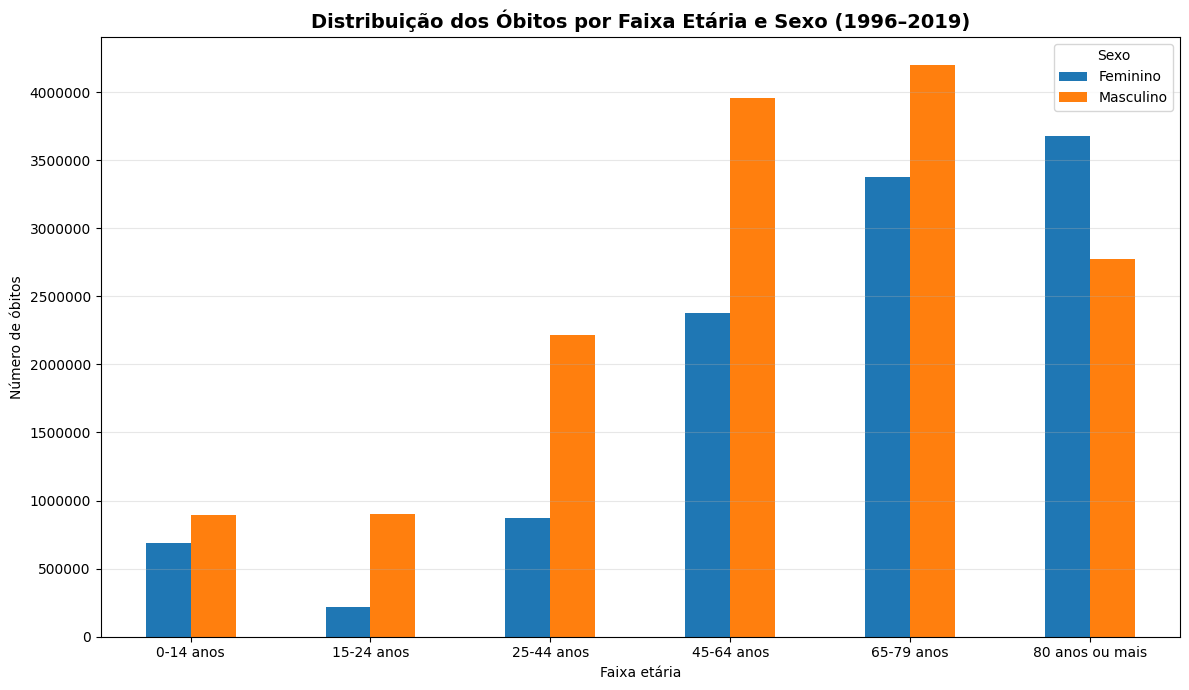

In [ ]:
# ============================================================
# EDA 5 — GRÁFICO DE ÓBITOS POR FAIXA ETÁRIA E SEXO
# ============================================================

ordem_faixas = [
    '0-14 anos',
    '15-24 anos',
    '25-44 anos',
    '45-64 anos',
    '65-79 anos',
    '80 anos ou mais'
]

df_grafico_idade_sexo = (
    df_idade_sexo
    .pivot(
        index='faixa_etaria',
        columns='sexo_descricao',
        values='total_obitos'
    )
    .reindex(ordem_faixas)
)

df_grafico_idade_sexo.plot(
    kind='bar',
    figsize=(12, 7)
)

plt.title(
    'Distribuição dos Óbitos por Faixa Etária e Sexo (1996–2019)',
    fontsize=14,
    fontweight='bold'
)

plt.xlabel('Faixa etária')
plt.ylabel('Número de óbitos')

plt.xticks(rotation=0)
plt.ticklabel_format(style='plain', axis='y')

plt.legend(title='Sexo')
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

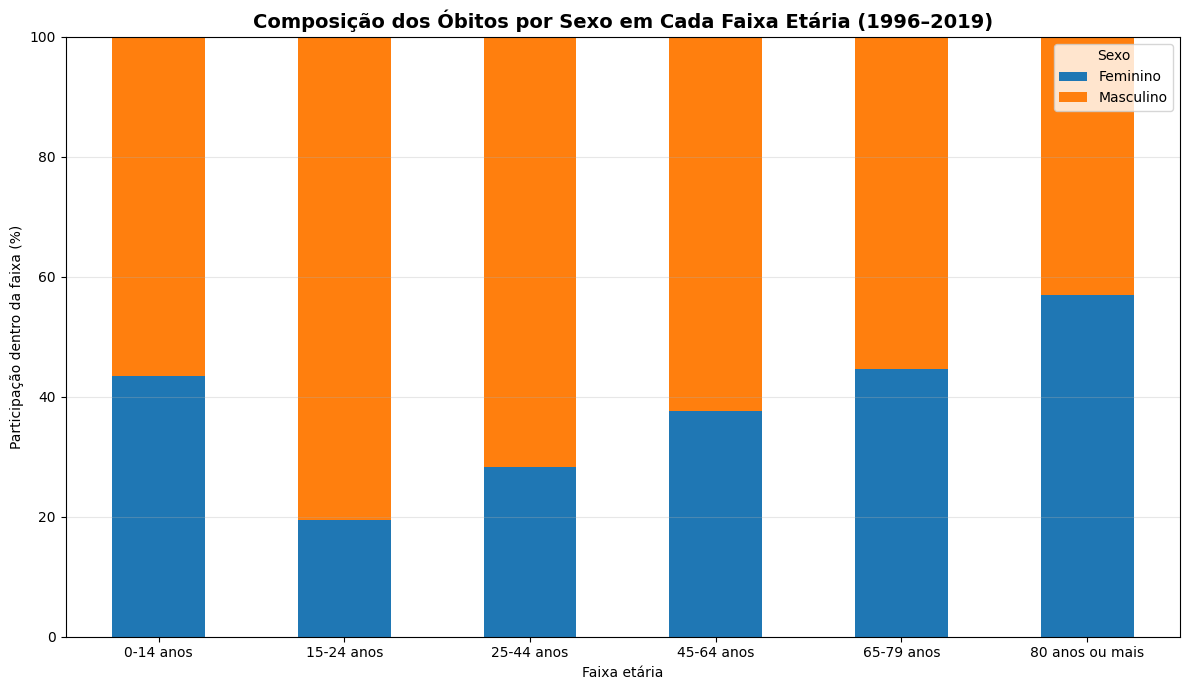

In [ ]:
# ============================================================
# EDA 5 — COMPOSIÇÃO PERCENTUAL POR SEXO EM CADA FAIXA ETÁRIA
# ============================================================

df_grafico_pct = (
    df_idade_sexo_pct
    .pivot(
        index='faixa_etaria',
        columns='sexo_descricao',
        values='percentual_na_faixa'
    )
    .reindex(ordem_faixas)
)

df_grafico_pct.plot(
    kind='bar',
    stacked=True,
    figsize=(12, 7)
)

plt.title(
    'Composição dos Óbitos por Sexo em Cada Faixa Etária (1996–2019)',
    fontsize=14,
    fontweight='bold'
)

plt.xlabel('Faixa etária')
plt.ylabel('Participação dentro da faixa (%)')

plt.xticks(rotation=0)
plt.ylim(0, 100)

plt.legend(title='Sexo')
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

###  Insight — Perfil dos óbitos por faixa etária e sexo

A mortalidade registrada entre 1996 e 2019 apresenta forte concentração nas faixas etárias mais avançadas. A faixa de **65–79 anos concentrou 28,80% dos óbitos**, seguida por **80 anos ou mais (24,54%)** e **45–64 anos (24,09%)**. Juntas, as faixas a partir de 45 anos representam aproximadamente **77,4% dos óbitos registrados**.

Considerando o sexo, **57,14% dos óbitos foram masculinos** e **42,80% femininos**, enquanto apenas 0,06% estavam classificados como não informados.

O cruzamento entre sexo e faixa etária revelou diferenças importantes na composição dos óbitos. Entre **15–24 anos, 80,62% dos óbitos foram masculinos**, maior predominância masculina entre as faixas analisadas. Entre **25–44 anos**, os homens também representaram a maioria, com **71,74%**.

Essa diferença diminui progressivamente nas faixas etárias mais elevadas. Entre **45–64 anos**, a participação masculina foi de **62,42%**, passando para **55,41% entre 65–79 anos**.

Na faixa de **80 anos ou mais ocorre uma inversão do padrão**, com as mulheres representando **57,04% dos óbitos** e os homens 42,96%.

Os resultados mostram que a composição dos óbitos por sexo varia substancialmente conforme a faixa etária, sendo a predominância masculina particularmente elevada entre adolescentes e adultos jovens e diminuindo com o avanço da idade.

**Nota metodológica:** os resultados representam a distribuição dos óbitos registrados, e não o risco de mortalidade de homens e mulheres. A comparação de risco exigiria denominadores populacionais específicos por sexo e faixa etária.

In [ ]:
# ============================================================
# EDA 6 — COMPLETUDE DA INFORMAÇÃO DE RAÇA/COR
# ============================================================

query_completude_raca = """
SELECT
    ano,

    SUM(numero_obitos) AS total_obitos,

    SUM(
        CASE
            WHEN raca_cor_descricao = 'Não informado'
            THEN numero_obitos
            ELSE 0
        END
    ) AS obitos_raca_nao_informada,

    ROUND(
        100 * SAFE_DIVIDE(
            SUM(
                CASE
                    WHEN raca_cor_descricao = 'Não informado'
                    THEN numero_obitos
                    ELSE 0
                END
            ),
            SUM(numero_obitos)
        ),
        2
    ) AS percentual_nao_informado

FROM
    `saude-sim-brasil.mortalidade_brasil.base_perfil_mortalidade`

GROUP BY
    ano

ORDER BY
    ano
"""

df_completude_raca = client.query(
    query_completude_raca
).to_dataframe()

df_completude_raca

,ano,total_obitos,obitos_raca_nao_informada,percentual_nao_informado
0,1996,908883,878725,96.68
1,1997,903516,513499,56.83
2,1998,931895,335467,36.00
3,1999,938658,247953,26.42
4,2000,946686,150563,15.90
5,2001,961492,131999,13.73
6,2002,982807,117757,11.98
7,2003,1002340,103338,10.31
8,2004,1024073,96356,9.41
9,2005,1006827,85795,8.52


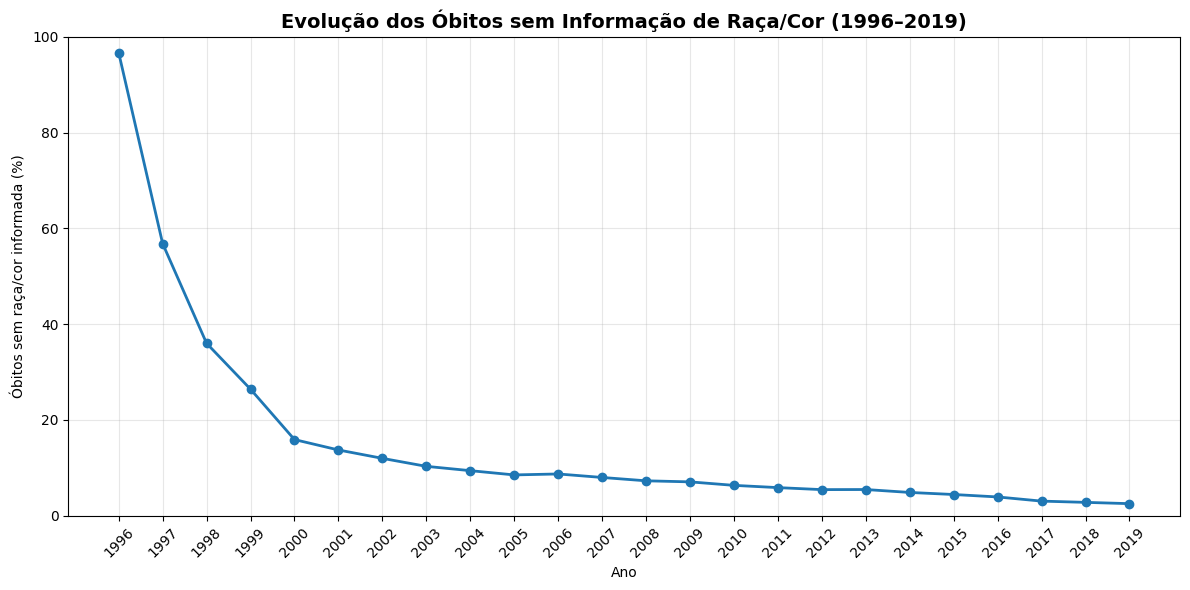

In [ ]:
# ============================================================
# EDA 6 — EVOLUÇÃO DOS REGISTROS SEM RAÇA/COR INFORMADA
# ============================================================

plt.figure(figsize=(12, 6))

plt.plot(
    df_completude_raca['ano'],
    df_completude_raca['percentual_nao_informado'],
    marker='o',
    linewidth=2
)

plt.title(
    'Evolução dos Óbitos sem Informação de Raça/Cor (1996–2019)',
    fontsize=14,
    fontweight='bold'
)

plt.xlabel('Ano')
plt.ylabel('Óbitos sem raça/cor informada (%)')

plt.xticks(
    df_completude_raca['ano'],
    rotation=45
)

plt.ylim(0, 100)

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# EDA 6 — IDENTIFICAÇÃO DOS ANOS COM COMPLETUDE >= 95%
# ============================================================

df_periodo_raca = df_completude_raca[
    df_completude_raca['percentual_nao_informado'] <= 5
].copy()

df_periodo_raca

,ano,total_obitos,obitos_raca_nao_informada,percentual_nao_informado
18,2014,1223152,59417,4.86
19,2015,1260774,55903,4.43
20,2016,1306311,51204,3.92
21,2017,1309729,40010,3.05
22,2018,1313887,36611,2.79
23,2019,1347263,33978,2.52


In [ ]:
# ============================================================
# EDA 6 — DISTRIBUIÇÃO DOS ÓBITOS POR RAÇA/COR
# PERÍODO COM COMPLETUDE >= 95%: 2014–2019
# ============================================================

query_raca = """
SELECT
    raca_cor_descricao,
    SUM(numero_obitos) AS total_obitos,

    ROUND(
        100 * SAFE_DIVIDE(
            SUM(numero_obitos),
            SUM(SUM(numero_obitos)) OVER()
        ),
        2
    ) AS percentual_obitos

FROM
    `saude-sim-brasil.mortalidade_brasil.base_perfil_mortalidade`

WHERE
    ano BETWEEN 2014 AND 2019

GROUP BY
    raca_cor_descricao

ORDER BY
    total_obitos DESC
"""

df_raca = client.query(query_raca).to_dataframe()

df_raca

,raca_cor_descricao,total_obitos,percentual_obitos
0,Branca,3953415,50.94
1,Parda,2871645,37.00
2,Preta,592076,7.63
3,Não informado,277123,3.57
4,Amarela,43320,0.56
5,Indígena,23537,0.30


In [ ]:
# ============================================================
# EDA 6 — EVOLUÇÃO DA COMPOSIÇÃO DOS ÓBITOS POR RAÇA/COR
# ============================================================

query_evolucao_raca = """
WITH raca_ano AS (

    SELECT
        ano,
        raca_cor_descricao,
        SUM(numero_obitos) AS total_obitos

    FROM
        `saude-sim-brasil.mortalidade_brasil.base_perfil_mortalidade`

    WHERE
        ano BETWEEN 2014 AND 2019

    GROUP BY
        ano,
        raca_cor_descricao
),

total_ano AS (

    SELECT
        ano,
        SUM(total_obitos) AS total_obitos_ano

    FROM raca_ano

    GROUP BY ano
)

SELECT
    r.ano,
    r.raca_cor_descricao,
    r.total_obitos,

    ROUND(
        100 * SAFE_DIVIDE(
            r.total_obitos,
            t.total_obitos_ano
        ),
        2
    ) AS percentual_ano

FROM raca_ano r

LEFT JOIN total_ano t
    ON r.ano = t.ano

ORDER BY
    r.ano,
    r.raca_cor_descricao
"""

df_evolucao_raca = client.query(
    query_evolucao_raca
).to_dataframe()

df_evolucao_raca

,ano,raca_cor_descricao,total_obitos,percentual_ano
0,2014,Amarela,6751,0.55
1,2014,Branca,628020,51.34
2,2014,Indígena,3622,0.30
3,2014,Não informado,59417,4.86
4,2014,Parda,433147,35.41
5,2014,Preta,92195,7.54
6,2015,Amarela,7046,0.56
7,2015,Branca,643262,51.02
8,2015,Indígena,3629,0.29
9,2015,Não informado,55903,4.43


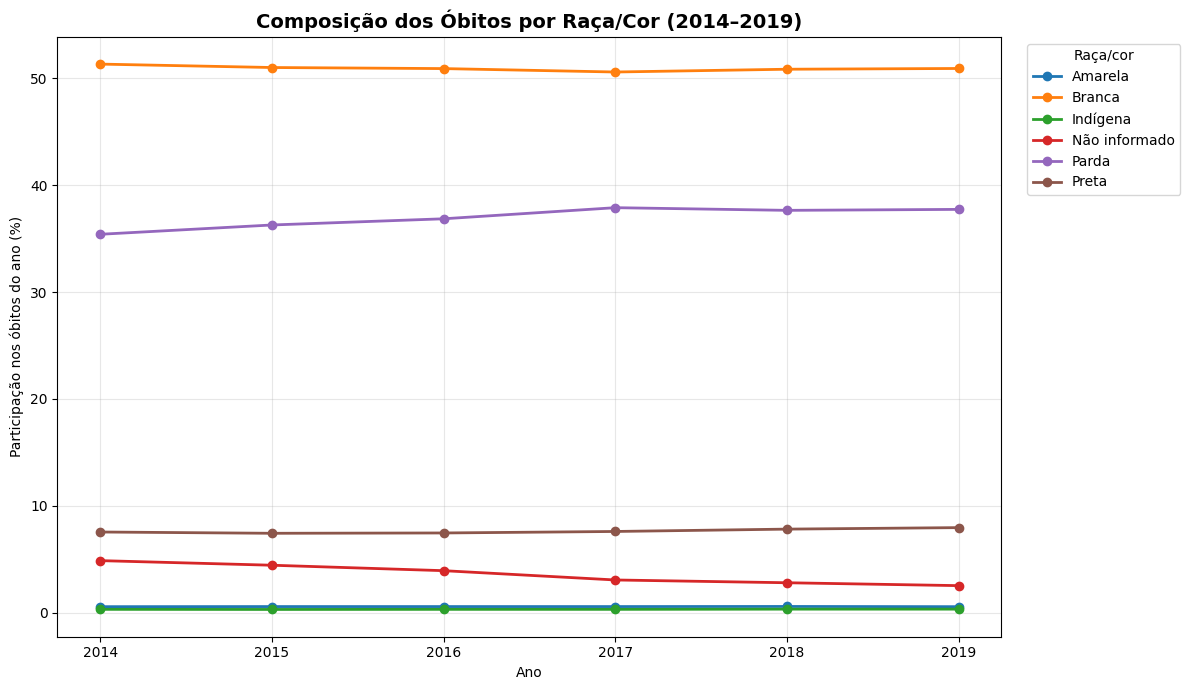

In [ ]:
# ============================================================
# EDA 6 — GRÁFICO DA EVOLUÇÃO POR RAÇA/COR
# ============================================================

plt.figure(figsize=(12, 7))

for categoria in df_evolucao_raca['raca_cor_descricao'].unique():

    dados = df_evolucao_raca[
        df_evolucao_raca['raca_cor_descricao'] == categoria
    ]

    plt.plot(
        dados['ano'],
        dados['percentual_ano'],
        marker='o',
        linewidth=2,
        label=categoria
    )

plt.title(
    'Composição dos Óbitos por Raça/Cor (2014–2019)',
    fontsize=14,
    fontweight='bold'
)

plt.xlabel('Ano')
plt.ylabel('Participação nos óbitos do ano (%)')

plt.xticks(range(2014, 2020))

plt.legend(
    title='Raça/cor',
    bbox_to_anchor=(1.02, 1),
    loc='upper left'
)

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

###  Insight — Composição dos óbitos por raça/cor

A análise da variável raça/cor exigiu uma avaliação prévia de sua completude. Em 1996, **96,68% dos óbitos não apresentavam informação de raça/cor**, percentual que caiu progressivamente até atingir **2,52% em 2019**.

Para reduzir o impacto da ausência de informação, foi adotado como critério metodológico utilizar, nas análises de composição por raça/cor, apenas anos com **pelo menos 95% dos óbitos com essa informação disponível**. O primeiro ano que atende ao critério é 2014, definindo o período analítico de **2014 a 2019**.

Nesse período, a categoria **Branca representou 50,94% dos óbitos registrados**, seguida por **Parda (37,00%)**, **Preta (7,63%)**, **Amarela (0,56%)** e **Indígena (0,30%)**. Os registros classificados como **Não informado representaram 3,57%**.

Entre 2014 e 2019, a participação da categoria Branca permaneceu relativamente estável, passando de **51,34% para 50,93%**. A categoria Parda passou de **35,41% para 37,74%**, enquanto a categoria Preta passou de **7,54% para 7,95%**.

No mesmo período, os registros sem informação de raça/cor diminuíram de **4,86% para 2,52%**, indicando melhora contínua na completude dessa variável.

**Nota metodológica:** esses percentuais descrevem a composição dos óbitos registrados e não representam taxas ou riscos de mortalidade por raça/cor. Comparações de risco exigiriam denominadores populacionais correspondentes a cada grupo. Além disso, mudanças na composição devem ser interpretadas considerando simultaneamente a redução dos registros sem informação.